# Etapa 3. Regresión logística múltiple
**Reto clima: vegetación y contaminación (SIMA, Monterrey)**

Modelo de dependencia: probabilidad de que la concentración **mensual** de un contaminante (PM10, PM2.5, NO2) sea *alta* en función de la vegetación (NDVI, cobertura verde) y la meteorología.

Estructura (misma numeración que el reporte, sección 5):
0. Configuración · 1. Datos · 2. Variable respuesta · 3. Preparación · 4. Multicolinealidad
5. Especificación y resultados del modelo · 6. Validación de supuestos · 7. Eficiencia y errores · 8. Variables más importantes

# Configuración

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from scipy import stats
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.metrics import (accuracy_score, roc_auc_score, roc_curve, confusion_matrix,
                             precision_score, recall_score, f1_score)

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:.3f}".format)

# --- Parámetros que se pueden cambiar ---
RUTA = "../Exploracion_descriptiva/tablas/base_analitica_mensual.csv"
RADIO = 500                          # radio (m) de NDVI y cobertura verde: 100, 300, 500 o 1000
CONTAMINANTES = ["PM10", "PM2.5", "NO2"]
PERCENTIL = 50                       # "alto" = por encima de este percentil de cada contaminante

# Carga de datos

In [2]:
base = pd.read_csv(RUTA)
print(base.shape)
base[["estacion", "fecha_mes", "temporada", "PM10", "PM2.5", "NO2", "TOUT", "RH", "RAINF", "WSR",
      f"ndvi_{RADIO}", f"verde_{RADIO}"]].head()

(360, 36)


,estacion,fecha_mes,temporada,PM10,PM2.5,NO2,TOUT,RH,RAINF,WSR,ndvi_500,verde_500
0,CE,2024-01,seca,80.480,31.496,24.347,14.340,55.343,0.000,6.074,0.153,0.000
1,CE,2024-02,seca,73.252,NaN,22.755,19.624,45.762,0.000,6.972,0.147,0.000
2,CE,2024-03,seca,66.381,22.894,17.515,21.376,51.811,0.000,7.559,0.180,0.000
3,CE,2024-04,seca,68.032,NaN,14.553,24.401,50.329,0.000,8.114,0.165,0.000
4,CE,2024-05,húmeda,78.591,NaN,12.759,29.792,52.475,0.920,9.780,0.143,0.000


# Variable respuesta binaria
Para cada contaminante: `y = 1` si el promedio mensual de la estación-mes supera el percentil `PERCENTIL` (por defecto la mediana) de ese contaminante, `y = 0` si no.
Con la mediana las clases quedan balanceadas. Si el equipo prefiere un umbral normativo (NOM), se puede reemplazar `umbrales` por valores fijos.

In [3]:
# Umbral por contaminante (percentil sobre los meses válidos)
umbrales = {c: base[c].quantile(PERCENTIL / 100) for c in CONTAMINANTES}
# Ejemplo de umbral fijo: umbrales = {"PM10": 70, "PM2.5": 41, "NO2": 21}

resumen_y = []
for c in CONTAMINANTES:
    validos = base[c].dropna()
    resumen_y.append({"contaminante": c, "umbral": umbrales[c], "n_validos": len(validos),
                      "n_alto (y=1)": int((validos > umbrales[c]).sum()),
                      "% alto": 100 * (validos > umbrales[c]).mean()})
pd.DataFrame(resumen_y)

,contaminante,umbral,n_validos,n_alto (y=1),% alto
0,PM10,54.113,353,176,49.858
1,PM2.5,19.243,220,110,50.000
2,NO2,13.660,326,163,50.000


# Preparación de los datos
- Predictores: NDVI y cobertura verde (radio elegido), temperatura, humedad, lluvia, viento y temporada húmeda (controla la estacionalidad).
- La lluvia es muy asimétrica → se usa `log(1 + lluvia)`.
- Las variables continuas se **estandarizan** (z-score): los coeficientes quedan comparables y los odds ratio se leen "por cada 1 desviación estándar".
- Se trabaja con casos completos (se eliminan filas con faltantes en y o en algún predictor).

In [4]:
base["RAINF_log"] = np.log1p(base["RAINF"])
base["humeda"] = (base["temporada"] == "húmeda").astype(int)

CONT = [f"ndvi_{RADIO}", f"verde_{RADIO}", "TOUT", "RH", "RAINF_log", "WSR"]   # continuas

def preparar(cont):
    """Devuelve (y, X estandarizada, datos completos) para un contaminante."""
    d = base.dropna(subset=[cont] + CONT).copy()
    d["y"] = (d[cont] > umbrales[cont]).astype(int)
    X = d[CONT].copy()
    X = (X - X.mean()) / X.std()                     # z-score
    X["humeda"] = d["humeda"]
    return d["y"], sm.add_constant(X), d

datos = {c: preparar(c) for c in CONTAMINANTES}
pd.DataFrame({c: {"n usado": len(datos[c][0]), "% y=1": 100 * datos[c][0].mean(),
                  "n estaciones": datos[c][2]["estacion"].nunique()} for c in CONTAMINANTES}).T

,n usado,% y=1,n estaciones
PM10,284.000,50.352,15.000
PM2.5,162.000,53.086,11.000
NO2,264.000,51.136,15.000


# Multicolinealidad (VIF)
VIF > 5 (o > 10) indica predictores muy correlacionados entre sí. Ojo: `verde` y `construido` son casi espejo, por eso solo se usa `verde`.

In [5]:
vif = {}
for c in CONTAMINANTES:
    X = datos[c][1]
    vif[c] = pd.Series([variance_inflation_factor(X.values, i) for i in range(X.shape[1])], index=X.columns)
pd.DataFrame(vif).drop(index="const")

,PM10,PM2.5,NO2
ndvi_500,2.946,1.606,2.849
verde_500,2.628,1.178,2.568
TOUT,3.773,3.368,3.735
RH,2.053,1.848,1.963
RAINF_log,1.709,1.372,1.661
WSR,1.678,1.636,1.653
humeda,4.175,4.016,4.077


# Especificación y resultados del modelo
Modelo logit: $\log\frac{p}{1-p} = \beta_0 + \beta_1 x_1 + \dots + \beta_k x_k$, con $p = P(y=1)$.
- Se ajusta por máxima verosimilitud (`statsmodels.Logit`).
- Errores estándar **agrupados por estación** (las mediciones de una misma estación no son independientes).
- Se reporta el odds ratio: $OR = e^{\beta}$ (por 1 DE en las continuas). $OR>1$ sube la probabilidad de nivel alto; $OR<1$ la baja.

In [6]:
modelos = {}
tablas = {}
for c in CONTAMINANTES:
    y, X, d = datos[c]
    m = sm.Logit(y, X).fit(disp=0, cov_type="cluster", cov_kwds={"groups": d["estacion"]})
    modelos[c] = m
    ic = np.exp(m.conf_int())
    tablas[c] = pd.DataFrame({"coef": m.params, "OR": np.exp(m.params), "IC95_inf": ic[0], "IC95_sup": ic[1],
                              "p": m.pvalues})
    print(f"\n{c} n={int(m.nobs)} | pseudo-R² McFadden={m.prsquared:.3f} | AIC={m.aic:.1f}")
    display(tablas[c])


PM10 n=284 | pseudo-R² McFadden=0.231 | AIC=318.6


,coef,OR,IC95_inf,IC95_sup,p
const,0.619,1.858,0.863,4.001,0.114
ndvi_500,0.453,1.573,0.887,2.789,0.121
verde_500,-0.547,0.579,0.368,0.910,0.018
TOUT,-0.324,0.723,0.341,1.532,0.397
RH,-0.491,0.612,0.342,1.096,0.098
RAINF_log,-0.363,0.696,0.427,1.133,0.145
WSR,0.146,1.158,0.629,2.130,0.638
humeda,-1.292,0.275,0.091,0.833,0.022



PM2.5 n=162 | pseudo-R² McFadden=0.165 | AIC=202.9


,coef,OR,IC95_inf,IC95_sup,p
const,1.128,3.089,1.055,9.046,0.040
ndvi_500,-0.147,0.864,0.507,1.471,0.589
verde_500,-0.226,0.797,0.472,1.347,0.398
TOUT,0.279,1.322,0.761,2.297,0.322
RH,0.210,1.234,0.635,2.398,0.535
RAINF_log,-0.312,0.732,0.393,1.365,0.326
WSR,-0.067,0.935,0.506,1.729,0.831
humeda,-2.202,0.111,0.025,0.494,0.004



NO2 n=264 | pseudo-R² McFadden=0.341 | AIC=257.2


,coef,OR,IC95_inf,IC95_sup,p
const,-0.173,0.841,0.342,2.072,0.707
ndvi_500,0.009,1.009,0.400,2.543,0.985
verde_500,-0.886,0.412,0.161,1.054,0.064
TOUT,-1.691,0.184,0.067,0.506,0.001
RH,-0.922,0.398,0.169,0.939,0.035
RAINF_log,0.238,1.269,0.631,2.552,0.504
WSR,-0.485,0.615,0.299,1.269,0.188
humeda,0.632,1.881,0.536,6.594,0.324


# Validación de supuestos

### Linealidad del logit
Cada predictor continuo debe tener relación lineal con el logit de $p$. Se divide el predictor en 5 grupos (cuantiles) y se grafica el logit de la proporción de `y=1` contra el promedio del predictor; los puntos deberían seguir aproximadamente una recta.

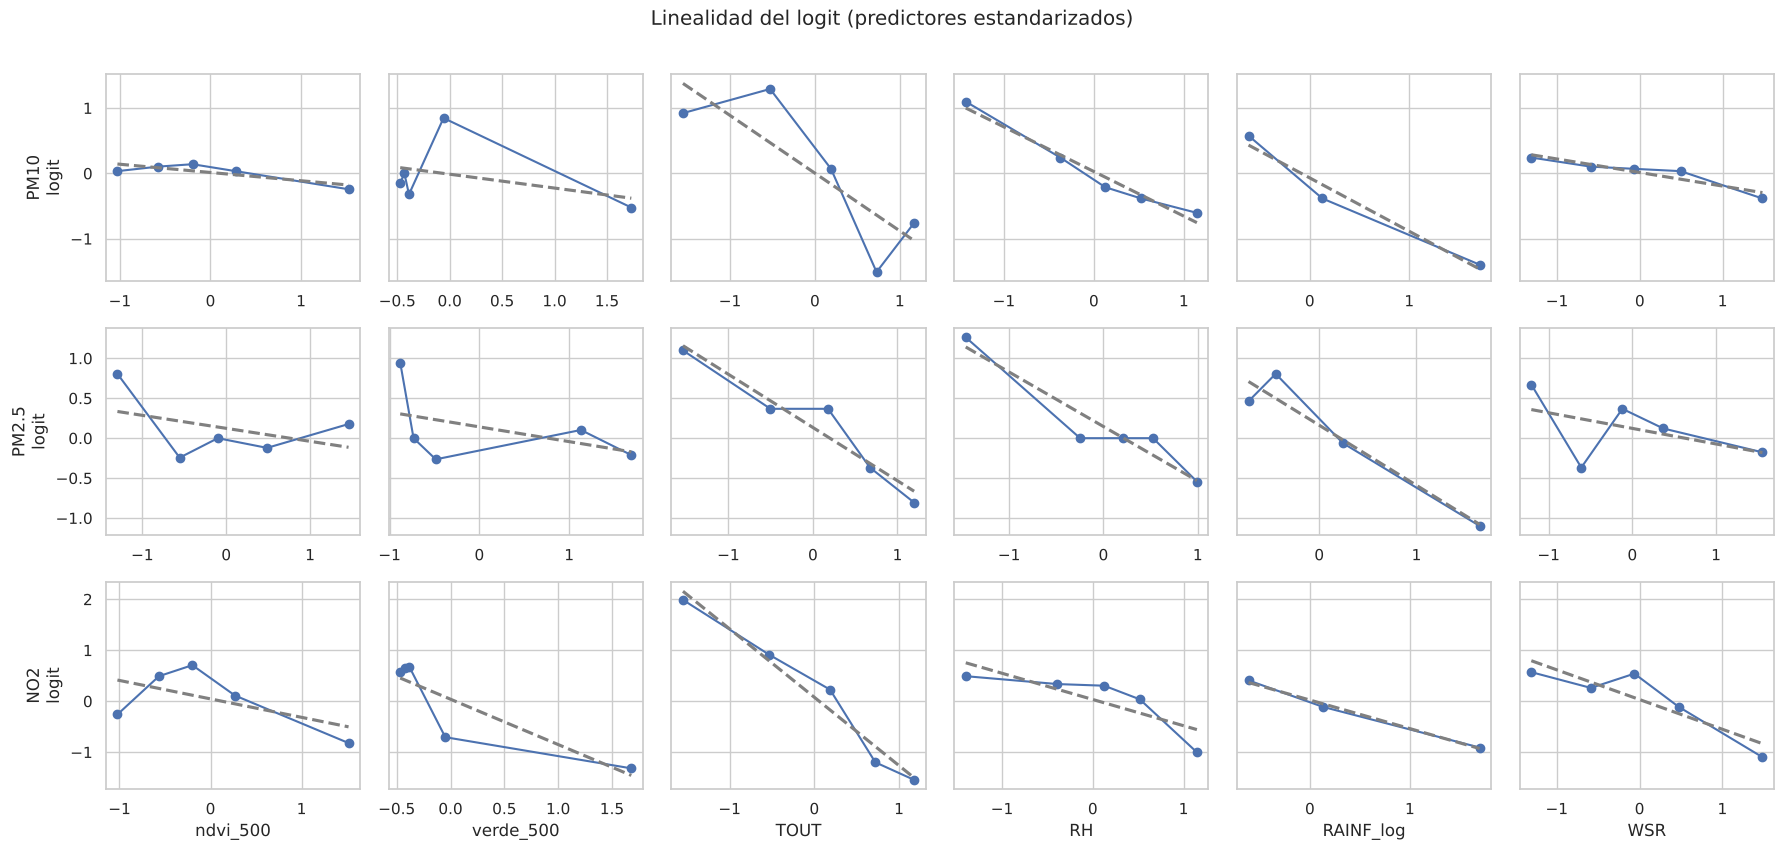

In [7]:
def logit_emp(y, x, bins=5):
    g = pd.DataFrame({"x": x, "y": y})
    g["b"] = pd.qcut(g["x"], bins, duplicates="drop")
    t = g.groupby("b", observed=True).agg(x=("x", "mean"), s=("y", "sum"), n=("y", "size"))
    t["logit"] = np.log((t.s + 0.5) / (t.n - t.s + 0.5))          # +0.5 evita logit infinito
    return t

fig, axes = plt.subplots(len(CONTAMINANTES), len(CONT), figsize=(3 * len(CONT), 2.8 * len(CONTAMINANTES)), sharey="row")
for i, c in enumerate(CONTAMINANTES):
    y, X, d = datos[c]
    for j, v in enumerate(CONT):
        t = logit_emp(y, X[v])
        ax = axes[i, j]
        ax.plot(t.x, t.logit, "o-")
        sns.regplot(x=t.x, y=t.logit, scatter=False, ci=None, color="gray", line_kws={"ls": "--"}, ax=ax)
        ax.set_xlabel(v if i == len(CONTAMINANTES) - 1 else "")
        ax.set_ylabel(f"{c}\nlogit" if j == 0 else "")
plt.suptitle("Linealidad del logit (predictores estandarizados)", y=1.01)
plt.tight_layout(); plt.show()

### Observaciones influyentes
Distancia de Cook: mide cuánto cambiaría el modelo al quitar una observación. Referencia usual: $4/n$.

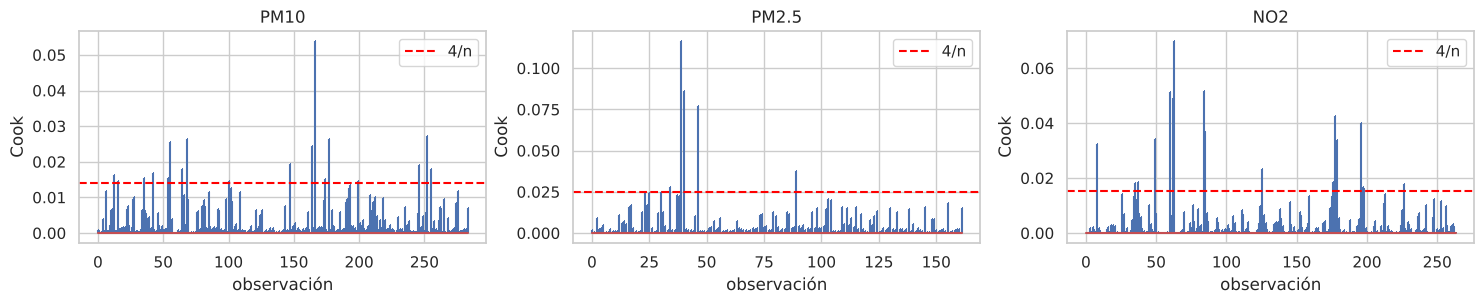

Top 5 influyentes PM10


,estacion,fecha_mes,PM10,cook
220,SE,2024-05,74.340,0.054
324,SO2,2025-01,53.982,0.027
86,NE3,2025-03,75.764,0.027
231,SE,2025-04,49.604,0.027
73,NE3,2024-02,54.359,0.026


Top 5 influyentes PM2.5


,estacion,fecha_mes,PM2.5,cook
170,NTE,2024-03,14.009,0.117
171,NTE,2024-04,16.871,0.086
197,NTE2,2024-06,19.408,0.077
249,SE2,2024-10,21.440,0.038
138,NO2,2025-07,20.490,0.028


Top 5 influyentes NO2


,estacion,fecha_mes,NO2,cook
86,NE3,2025-03,15.557,0.070
120,NO2,2024-01,6.211,0.052
83,NE3,2024-12,15.022,0.051
85,NE3,2025-02,16.773,0.049
252,SE2,2025-01,5.926,0.042


In [8]:
fig, axes = plt.subplots(1, len(CONTAMINANTES), figsize=(5 * len(CONTAMINANTES), 3.2))
influyentes = {}
for ax, c in zip(axes, CONTAMINANTES):
    y, X, d = datos[c]
    glm = sm.GLM(y, X, family=sm.families.Binomial()).fit()
    cook = pd.Series(glm.get_influence().cooks_distance[0], index=d.index)
    ax.stem(range(len(cook)), cook.values, markerfmt=",")
    ax.axhline(4 / len(cook), color="red", ls="--", label="4/n")
    ax.set_title(c); ax.set_xlabel("observación"); ax.set_ylabel("Cook"); ax.legend()
    influyentes[c] = d.loc[cook.nlargest(5).index, ["estacion", "fecha_mes", c]].assign(cook=cook.nlargest(5))
plt.tight_layout(); plt.show()
for c in CONTAMINANTES:
    print(f"Top 5 influyentes {c}"); display(influyentes[c])

### Bondad de ajuste
- **Prueba de razón de verosimilitud** (modelo completo vs. solo constante).
- **Hosmer-Lemeshow**: compara casos observados vs. esperados en 10 grupos de probabilidad. $H_0$: el modelo ajusta bien (p alto = bien).
- **McFadden R²**: valores de 0.2–0.4 ya se consideran buen ajuste en logística.

In [9]:
def hosmer_lemeshow(y, p, g=10):
    t = pd.DataFrame({"y": y.values, "p": p.values})
    t["grupo"] = pd.qcut(t["p"], g, duplicates="drop")
    r = t.groupby("grupo", observed=True).agg(obs=("y", "sum"), esp=("p", "sum"), n=("y", "size"))
    chi2 = (((r.obs - r.esp) ** 2) / (r.esp * (1 - r.esp / r.n))).sum()
    gl = len(r) - 2
    return chi2, gl, 1 - stats.chi2.cdf(chi2, gl)

gof = []
for c in CONTAMINANTES:
    y, X, d = datos[c]
    m_ml = sm.Logit(y, X).fit(disp=0)                  # ajuste sin cluster solo para LR / HL
    hl, gl, p_hl = hosmer_lemeshow(y, m_ml.predict(X))
    gof.append({"contaminante": c, "McFadden R2": m_ml.prsquared, "LR chi2": m_ml.llr,
                "p (LR)": m_ml.llr_pvalue, "HL chi2": hl, "HL gl": gl, "p (HL)": p_hl})
pd.DataFrame(gof).set_index("contaminante")

,McFadden R2,LR chi2,p (LR),HL chi2,HL gl,p (HL)
contaminante,,,,,,
PM10,0.231,91.050,0.000,5.393,8,0.715
PM2.5,0.165,37.063,0.000,4.363,8,0.823
NO2,0.341,124.647,0.000,11.335,8,0.183


### Independencia de las observaciones
Una estación aporta hasta 24 meses, así que las observaciones no son del todo independientes. Se revisa si los residuos de Pearson tienen sesgo por estación; si lo hay, justifica los errores agrupados (ya usados en la sección 5).

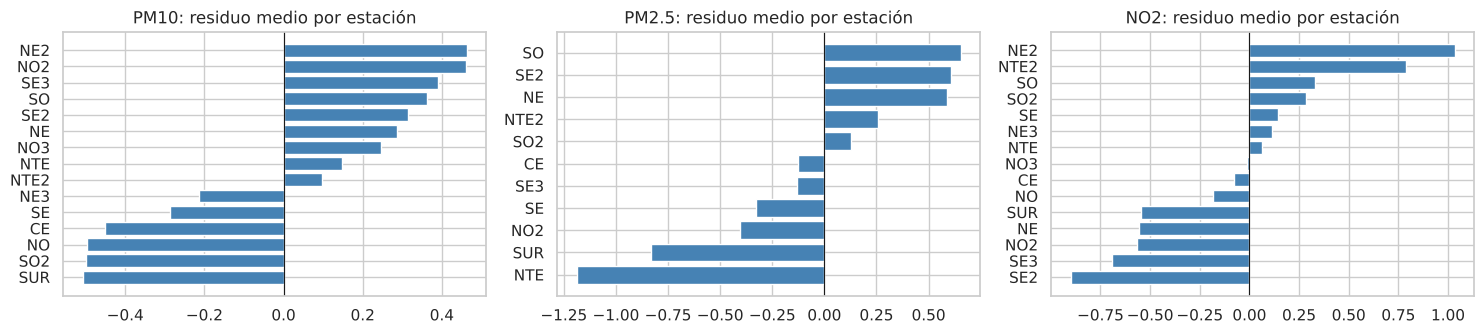

In [10]:
fig, axes = plt.subplots(1, len(CONTAMINANTES), figsize=(5 * len(CONTAMINANTES), 3.5), sharex=False)
for ax, c in zip(axes, CONTAMINANTES):
    y, X, d = datos[c]
    p = modelos[c].predict(X)
    res = ((y - p) / np.sqrt(p * (1 - p))).groupby(d["estacion"]).mean().sort_values()
    ax.barh(res.index, res.values, color="steelblue")
    ax.axvline(0, color="k", lw=0.8); ax.set_title(f"{c}: residuo medio por estación")
plt.tight_layout(); plt.show()

# Eficiencia del modelo y análisis de errores
Validación cruzada **por estación** (`GroupKFold`): el modelo se entrena con unas estaciones y se prueba en estaciones que nunca vio. Es una prueba más exigente que un split al azar, porque mide si el modelo generaliza a sitios nuevos. Umbral de clasificación: 0.5.

In [11]:
metricas, cv_pred = [], {}
for c in CONTAMINANTES:
    y, X, d = datos[c]
    Xc = X.drop(columns="const")
    n_folds = min(5, d["estacion"].nunique())
    pipe = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
    proba = cross_val_predict(pipe, Xc, y, groups=d["estacion"], cv=GroupKFold(n_folds), method="predict_proba")[:, 1]
    pred = (proba >= 0.5).astype(int)
    cv_pred[c] = pd.DataFrame({"y": y, "proba": proba, "pred": pred, "estacion": d["estacion"], "fecha_mes": d["fecha_mes"]})
    metricas.append({"contaminante": c, "exactitud": accuracy_score(y, pred), "AUC": roc_auc_score(y, proba),
                     "precisión": precision_score(y, pred), "sensibilidad": recall_score(y, pred),
                     "F1": f1_score(y, pred), "línea base": max(y.mean(), 1 - y.mean())})
pd.DataFrame(metricas).set_index("contaminante")

,exactitud,AUC,precisión,sensibilidad,F1,línea base
contaminante,,,,,,
PM10,0.662,0.631,0.636,0.769,0.696,0.504
PM2.5,0.654,0.588,0.683,0.651,0.667,0.531
NO2,0.758,0.814,0.789,0.719,0.752,0.511


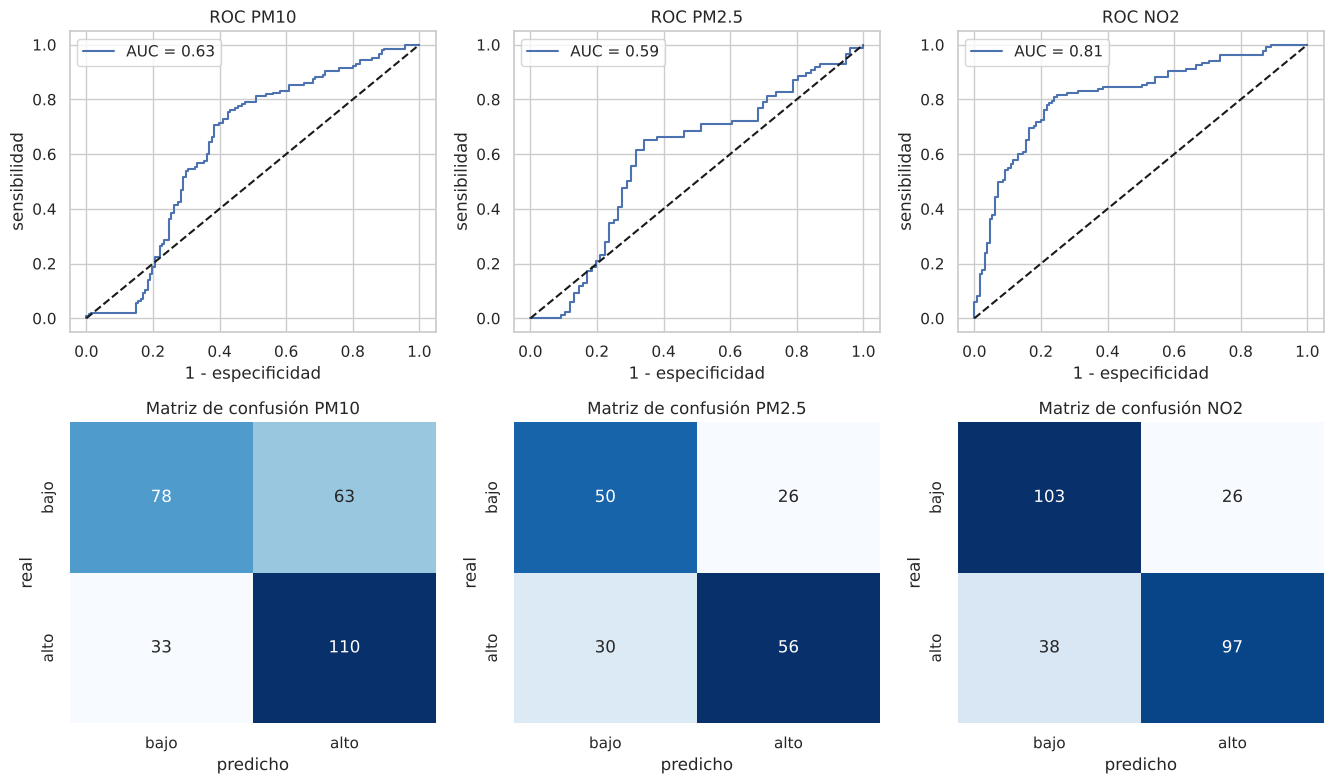

In [12]:
fig, axes = plt.subplots(2, len(CONTAMINANTES), figsize=(4.5 * len(CONTAMINANTES), 8))
for j, c in enumerate(CONTAMINANTES):
    r = cv_pred[c]
    fpr, tpr, _ = roc_curve(r.y, r.proba)
    axes[0, j].plot(fpr, tpr, label=f"AUC = {roc_auc_score(r.y, r.proba):.2f}")
    axes[0, j].plot([0, 1], [0, 1], "k--"); axes[0, j].set_title(f"ROC {c}")
    axes[0, j].set_xlabel("1 - especificidad"); axes[0, j].set_ylabel("sensibilidad"); axes[0, j].legend()
    sns.heatmap(confusion_matrix(r.y, r.pred), annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[1, j],
                xticklabels=["bajo", "alto"], yticklabels=["bajo", "alto"])
    axes[1, j].set_title(f"Matriz de confusión {c}"); axes[1, j].set_xlabel("predicho"); axes[1, j].set_ylabel("real")
plt.tight_layout(); plt.show()

### Análisis de errores
Dónde se equivoca el modelo: por estación y por mes.

PM10


,tasa_error,errores,n
estacion,,,
NE3,0.875,21,24
SO2,0.435,10,23
SE3,0.409,9,22
NO,0.375,6,16
NE,0.333,2,6


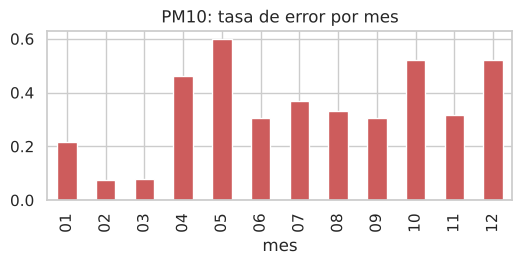

PM2.5


,tasa_error,errores,n
estacion,,,
NTE,1.000,2,2
SE2,0.800,16,20
NO2,0.438,7,16
SE3,0.389,7,18
SO,0.300,3,10


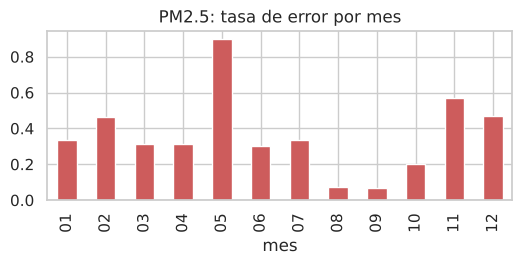

NO2


,tasa_error,errores,n
estacion,,,
NE2,0.474,9,19
NTE2,0.435,10,23
SE2,0.421,8,19
NE,0.333,2,6
NO2,0.300,6,20


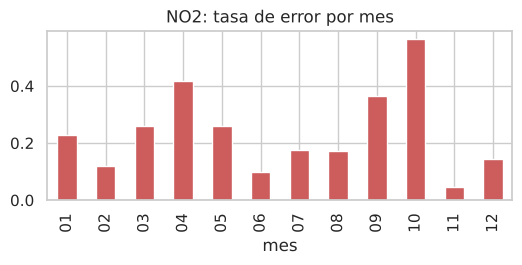

In [13]:
for c in CONTAMINANTES:
    r = cv_pred[c].assign(error=lambda t: (t.y != t.pred).astype(int), mes=lambda t: t.fecha_mes.str[-2:])
    por_est = r.groupby("estacion").error.agg(["mean", "sum", "size"]).rename(columns={"mean": "tasa_error", "sum": "errores", "size": "n"})
    por_mes = r.groupby("mes").error.mean()
    print(f"{c}")
    display(por_est.sort_values("tasa_error", ascending=False).head(5))
    por_mes.plot.bar(figsize=(6, 2.2), title=f"{c}: tasa de error por mes", color="indianred"); plt.show()

# Variables más importantes
Odds ratio por 1 DE (IC 95 %, errores agrupados por estación). La línea en 1 = sin efecto; si el intervalo cruza el 1, el efecto no es significativo.

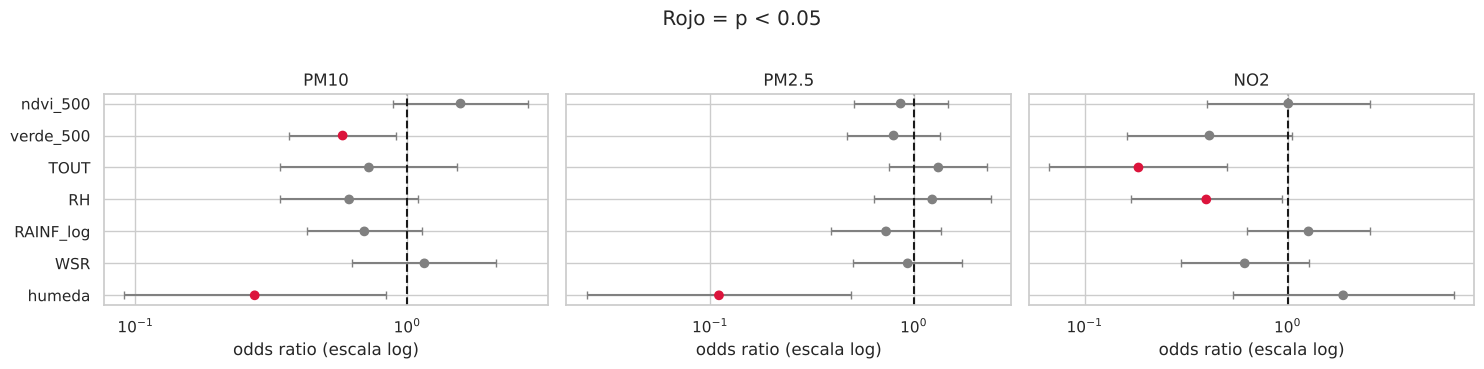

,PM10,PM2.5,NO2
|coef| estandarizado,,,
humeda,1.292,2.202,0.632
verde_500,0.547,0.226,0.886
RH,0.491,0.210,0.922
ndvi_500,0.453,0.147,0.009
RAINF_log,0.363,0.312,0.238
TOUT,0.324,0.279,1.691
WSR,0.146,0.067,0.485


In [14]:
fig, axes = plt.subplots(1, len(CONTAMINANTES), figsize=(5 * len(CONTAMINANTES), 3.6), sharey=True)
for ax, c in zip(axes, CONTAMINANTES):
    t = tablas[c].drop(index="const").iloc[::-1]
    sig = t.p < 0.05
    ax.errorbar(t.OR, range(len(t)), xerr=[t.OR - t.IC95_inf, t.IC95_sup - t.OR], fmt="none", ecolor="gray", capsize=3)
    ax.scatter(t.OR, range(len(t)), c=np.where(sig, "crimson", "gray"), zorder=3)
    ax.axvline(1, color="k", ls="--"); ax.set_xscale("log"); ax.set_title(c); ax.set_xlabel("odds ratio (escala log)")
    ax.set_yticks(range(len(t))); ax.set_yticklabels(t.index)
plt.suptitle("Rojo = p < 0.05", y=1.02); plt.tight_layout(); plt.show()

# Resumen: importancia = |coeficiente estandarizado|
imp = pd.DataFrame({c: tablas[c]["coef"].abs() for c in CONTAMINANTES}).drop(index="const")
imp.sort_values(CONTAMINANTES[0], ascending=False).rename_axis("|coef| estandarizado")